# French imbalance-settlement stress: report

ENTSO-E France, 1 January 2021 to 31 December 2024, 30-minute delivery intervals.

## 1. What $S_{short}$ and $S_{long}$ measure, and why they matter economically

A market participant (a balance-responsible party: a producer, supplier or trader) commits to a position for each delivery interval, mostly through the **day-ahead market**, which clears the day before at price $P_{DA}$. In real time, the participant rarely delivers exactly what it committed: a wind farm produces less than forecast, a factory consumes more than planned. The grid operator (RTE in France) balances the system and then **settles each participant's deviation (imbalance) at an imbalance price** that is only known after delivery.

There are two separate imbalance prices, because being short and being long are settled differently:

* **Short position** (delivered less, or consumed more, than committed). The missing energy is effectively bought back from the system at $P_{short}$. Compared with having bought it on the day-ahead market, the extra cost per MWh is
$$S_{short} = P_{short} - P_{DA}.$$
$S_{short}$ is large when the system as a whole is short: the grid operator has to activate expensive upward balancing (fast gas, imports, demand response), so the imbalance price spikes above day-ahead.

* **Long position** (delivered more, or consumed less, than committed). The surplus is effectively sold back to the system at $P_{long}$. Compared with having sold it on the day-ahead market, the revenue lost per MWh is
$$S_{long} = P_{DA} - P_{long}.$$
$S_{long}$ is large when the system is long: there is too much energy (for example high wind or solar, low demand), the operator activates downward balancing and the imbalance price collapses, sometimes below zero.

The sign of $S_{long}$ is flipped on purpose, so that for **both** positions **$S > 0$ means the outcome was worse than the day-ahead price**, and a larger $S$ means a bigger financial penalty. No absolute values are taken, because they would mix good and bad outcomes.

**Why this matters.** $S$ is the price of being wrong. For a renewable producer it is the cost of a forecast error, for a trader it is the risk of holding an open position into delivery, and for the system it signals how tight balancing was. A model that flags in advance the intervals where this penalty is likely to be **severe** helps a participant decide how much to hedge or re-trade in the intraday market before delivery.

In the data, the two kinds of severe stress almost never happen at the same time (see section 6): a system that is very short is not also very long, so they are modelled separately.

In [1]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
PROCESSED = ROOT / "Data" / "Processed"
table = pd.read_csv(PROCESSED / "modelling_table.csv")
saved = json.loads((PROCESSED / "thresholds.json").read_text())
order = ["train", "validation", "test"]
years = {"train": "2021-22", "validation": "2023", "test": "2024"}
print(f"{len(table):,} clean 30-minute intervals")
print(table["split"].value_counts().loc[order].rename(index=years).to_string())

67,927 clean 30-minute intervals
split
2021-22    34053
2023       16393
2024       17481


## 2. Distribution of $S_{short}$ and $S_{long}$

Before building any model, it helps to look at what the two stress variables look like. The histograms cover the central 98% of intervals (1st to 99th percentile), because the extremes stretch to several thousand EUR/MWh and would squash the picture; the table below gives the full range. The dashed lines mark the upper quartile (q75) and the 90th-percentile cut-off (q90) used to define severe stress, both from 2021-22.

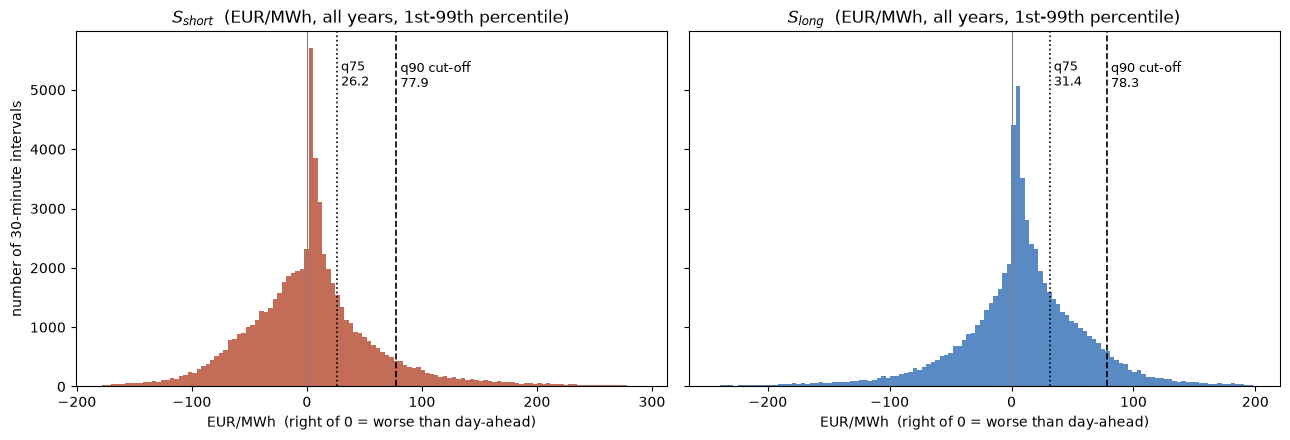

,mean,std,min,1st pct,5th pct,25th pct,median,75th pct,90th pct,95th pct,99th pct,max
S_short,6.21,98.40,-3686.15,-177.68,-88.33,-27.86,3.52,27.76,74.50,118.77,289.68,4117.98
S_long,7.56,94.69,-3552.70,-242.84,-91.55,-14.03,7.82,36.23,71.85,97.63,198.19,4170.79


In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"short": "#B5482F", "long": "#2F6DB5"}
for ax, side in zip(axes, ["short", "long"]):
    s = table[f"S_{side}"]
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s[s.between(lo, hi)], bins=120, range=(lo, hi), color=colors[side], alpha=0.8)
    tr = table.loc[table["split"] == "train", f"S_{side}"]
    for q, ls, lab in [(tr.quantile(0.75), ":", "q75"), (saved[f"q90_{side}"], "--", "q90 cut-off")]:
        ax.axvline(q, color="black", linestyle=ls, linewidth=1.2)
        ax.text(q, ax.get_ylim()[1] * 0.92, f" {lab}\n {q:.1f}", fontsize=9, va="top")
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"$S_{{{side}}}$  (EUR/MWh, all years, 1st-99th percentile)")
    ax.set_xlabel("EUR/MWh  (right of 0 = worse than day-ahead)")
axes[0].set_ylabel("number of 30-minute intervals")
plt.tight_layout()
plt.show()

pct = [0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
summary = table[["S_short", "S_long"]].describe(percentiles=pct).T
summary = summary.drop(columns="count").round(2)
ordinal = {"1%": "1st pct", "5%": "5th pct", "25%": "25th pct", "50%": "median", "75%": "75th pct",
           "90%": "90th pct", "95%": "95th pct", "99%": "99th pct"}
summary = summary.rename(columns=ordinal)
summary

## 3. Model 1: what goes in and what comes out

### The response variable

The model does not predict the euro amount of $S$. It predicts whether $S$ is **severe**, defined as above its 90th percentile $q_{90}$ (the top 10% of stress), estimated on the 2021-22 training years only and then kept fixed for 2023 and 2024:

$$Y_{short}(t) = \begin{cases} 1 & \text{if } S_{short}(t) > q_{90,short} \\ 0 & \text{otherwise} \end{cases} \qquad\qquad Y_{long}(t) = \begin{cases} 1 & \text{if } S_{long}(t) > q_{90,long} \\ 0 & \text{otherwise} \end{cases}$$

So there are two response variables and two separate models: one for severe short-side stress and one for severe long-side stress. Because $Y$ is 0 or 1, the model is a **logistic regression**, which outputs the probability that $Y = 1$.

### The explanatory variables

Only information that is **known after the day-ahead auction and before delivery** is used, so the model could actually be run in practice the day before. 17 variables in total; the continuous ones are standardised (z-scores) using 2021-22 means and standard deviations only.

| Variable | What it is | Why it could matter |
|---|---|---|
| `day_ahead_price` | French day-ahead price, EUR/MWh | the reference price that $S$ is measured against; high prices signal a tight system |
| `load_forecast` | day-ahead forecast of national demand, MW | high expected demand leaves less spare capacity for balancing |
| `wind_onshore_forecast` | day-ahead onshore wind forecast, MW | wind forecasts carry large errors, a main cause of imbalances |
| `solar_forecast` | day-ahead solar forecast, MW | same for solar; also drives midday surpluses |
| `scheduled_imports` | sum of day-ahead schedules from BE, DE_LU, CH, IT_NORD, ES, GB into France, MW | reliance on neighbours |
| `scheduled_exports` | sum of day-ahead schedules from France to those neighbours, MW | how much of French supply is committed abroad |
| `hour_sin`, `hour_cos` | time of day as a smooth cycle | stress follows daily patterns (morning ramp, evening peak) |
| `dow_1` ... `dow_6` | day of week (Monday is the baseline) | weekends and weekdays balance differently |
| `season_spring`, `season_summer`, `season_autumn` | season (winter is the baseline) | seasonal demand and renewable patterns |

**Left out on purpose.**
* `net_scheduled_imports` is exactly imports minus exports, so including it as well would make the coefficients impossible to separate.
* `wind_offshore_forecast` (and `residual_load_forecast`, which uses it) is blank for all of 2021-22, before French offshore farms reported, so a model trained on those years cannot learn from it.
* Anything only known **after** delivery (actual load, actual generation, physical flows, imbalance volumes and the imbalance prices themselves) is excluded, because using it would be looking into the future.

### How the model works

Each logistic regression adds up the inputs with weights $\beta$ and turns the sum into a probability between 0 and 1:

$$P\big(Y(t) = 1\big) = \sigma\Big(\beta_0 + \sum_{j=1}^{17} \beta_j \, x_j(t)\Big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

A positive $\beta_j$ means that a higher value of input $j$ makes severe stress more likely. The weights are estimated on 2021-22 only, with an L2 penalty whose strength is chosen on 2023; 2024 is used only for the final check. Code: `src/models/model_1_logistic_regression.py`.

## 4. The severity thresholds, recalculated on the cleaned data

After the cleaning steps (most recently removing the 44 intervals of 3 February 2021 with missing scheduled imports), the thresholds are recomputed here from scratch: the 90th percentile of $S$ over the 2021-22 training intervals only. They are compared with the values the pipeline saved in `thresholds.json`. For reference the table also shows the 75th percentile (upper quartile), which is **not** the cut-off used.

In [3]:
train = table[table["split"] == "train"]
rows = []
for side in ["short", "long"]:
    s = train[f"S_{side}"]
    q90 = s.quantile(0.90)
    rows.append({"stress": f"S_{side}",
                 "median": round(s.median(), 2),
                 "q75 (upper quartile)": round(s.quantile(0.75), 2),
                 "q90 recomputed (cut-off)": round(q90, 3),
                 "q90 saved by pipeline": round(saved[f"q90_{side}"], 3),
                 "match": abs(q90 - saved[f"q90_{side}"]) < 1e-9,
                 "labels consistent": bool(((table[f"S_{side}"] > q90).astype(int) == table[f"Y_{side}"]).all())})
pd.DataFrame(rows).set_index("stress")

,median,q75 (upper quartile),q90 recomputed (cut-off),q90 saved by pipeline,match,labels consistent
stress,,,,,,
S_short,5.75,26.18,77.860,77.860,True,True
S_long,8.47,31.36,78.268,78.268,True,True


## 5. How many intervals are severe ($Y = 1$)?

Counts of $Y = 1$, i.e. intervals where $S$ is above its fixed 2021-22 cut-off. In training the share is 10% by construction; in 2023 and 2024 it can differ, because the cut-off is held fixed rather than re-estimated.

In [4]:
counts = []
for side in ["short", "long"]:
    g = table.groupby("split")[f"Y_{side}"]
    for split in order:
        counts.append({"target": f"Y_{side}", "period": years[split],
                       "intervals": int(g.count()[split]),
                       "Y = 1": int(g.sum()[split]),
                       "share Y = 1": f"{g.mean()[split]:.1%}"})
    counts.append({"target": f"Y_{side}", "period": "all",
                   "intervals": len(table), "Y = 1": int(table[f"Y_{side}"].sum()),
                   "share Y = 1": f"{table[f'Y_{side}'].mean():.1%}"})
display(pd.DataFrame(counts).set_index(["target", "period"]))
both = int(((table["Y_short"] == 1) & (table["Y_long"] == 1)).sum())
print(f"Intervals severe on both sides at once: {both}")

intervals  Y = 1 share Y = 1
target  period                               
Y_short 2021-22      34053   3405       10.0%
        2023         16393   1176        7.2%
        2024         17481   1811       10.4%
        all          67927   6392        9.4%
Y_long  2021-22      34053   3406       10.0%
        2023         16393    868        5.3%
        2024         17481   1410        8.1%
        all          67927   5684        8.4%

Intervals severe on both sides at once: 2


## 6. How are $S_{short}$ and $S_{long}$ related?

### A built-in link

Adding the two definitions gives

$$S_{short} + S_{long} = (P_{short} - P_{DA}) + (P_{DA} - P_{long}) = P_{short} - P_{long},$$

the spread between the two imbalance prices. This spread is never negative and is usually small, so **when one stress is high, the other is pushed down by almost the same amount**. Economically: an interval where the system is very short (expensive to be short) is an interval where being long is rewarded, not penalised. The two variables are therefore close to mirror images, and both can only be severe together when the spread itself is huge.

correlation S_short vs S_long: Pearson -0.988, Spearman -0.956
S_short + S_long equals P_short - P_long on every interval: True
spread P_short - P_long: min 0.00, median 9.68, 90th pct 29.42 EUR/MWh


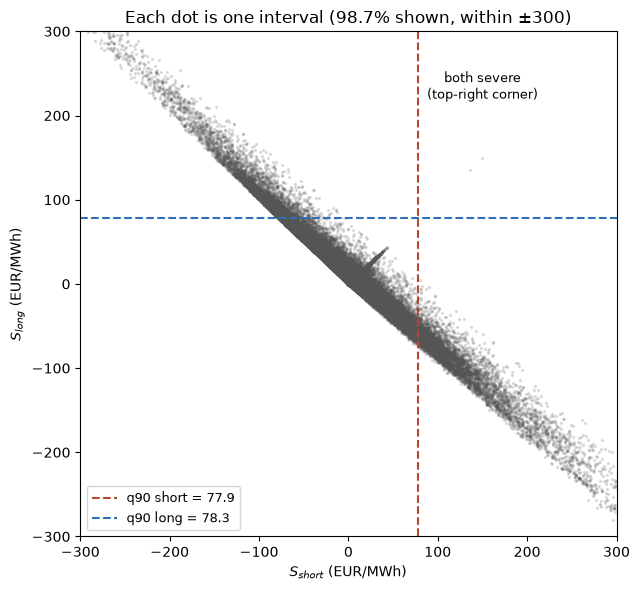

In [5]:
spread = table["price_short"] - table["price_long"]
print(f"correlation S_short vs S_long: Pearson {table['S_short'].corr(table['S_long']):.3f}, "
      f"Spearman {table['S_short'].corr(table['S_long'], method='spearman'):.3f}")
print(f"S_short + S_long equals P_short - P_long on every interval: "
      f"{bool(((table['S_short'] + table['S_long']) - spread).abs().max() < 0.02)}")
print(f"spread P_short - P_long: min {spread.min():.2f}, median {spread.median():.2f}, "
      f"90th pct {spread.quantile(0.9):.2f} EUR/MWh")

fig, ax = plt.subplots(figsize=(6.5, 6))
lim = (-300, 300)
inside = table["S_short"].between(*lim) & table["S_long"].between(*lim)
ax.scatter(table.loc[inside, "S_short"], table.loc[inside, "S_long"], s=2, alpha=0.15, color="#555555")
ax.axvline(saved["q90_short"], color="#B5482F", linestyle="--", label=f"q90 short = {saved['q90_short']:.1f}")
ax.axhline(saved["q90_long"], color="#2F6DB5", linestyle="--", label=f"q90 long = {saved['q90_long']:.1f}")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("$S_{short}$ (EUR/MWh)"); ax.set_ylabel("$S_{long}$ (EUR/MWh)")
ax.set_title(f"Each dot is one interval ({inside.mean():.1%} shown, within ±300)")
ax.text(150, 220, "both severe\n(top-right corner)", ha="center", fontsize=9)
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

### Are both ever severe at the same time?

The table cross-counts $Y_{short}$ and $Y_{long}$ over all 67,927 intervals.

In [6]:
cross = pd.crosstab(table["Y_short"], table["Y_long"], margins=True, margins_name="total")
cross.index = ["Y_short = 0", "Y_short = 1", "total"]
cross.columns = ["Y_long = 0", "Y_long = 1", "total"]
display(cross)
both = table[(table["Y_short"] == 1) & (table["Y_long"] == 1)]
print(f"Intervals with both = 1: {len(both)}, on {both['datetime_paris'].str[:10].nunique()} day(s)")
both[["datetime_paris", "day_ahead_price", "price_short", "price_long", "S_short", "S_long"]].round(2)

,Y_long = 0,Y_long = 1,total
Y_short = 0,55853,5682,61535
Y_short = 1,6390,2,6392
total,62243,5684,67927


Intervals with both = 1: 2, on 1 day(s)


,datetime_paris,day_ahead_price,price_short,price_long,S_short,S_long
21262,2022-04-04 07:30:00+02:00,2712.99,2848.64,2577.34,135.65,135.65
21264,2022-04-04 08:30:00+02:00,2987.78,3137.17,2838.39,149.39,149.39


### When only one side is severe, how close is the other side to its cut-off?

For every interval where exactly one of $Y_{short}$, $Y_{long}$ is 1, the table measures how far the **other** stress is below its own 90th-percentile cut-off:

$$\text{gap} = q_{90,\text{other}} - S_{\text{other}} \quad (> 0, \text{ in EUR/MWh})$$

A gap of 1 would mean the other side only just missed being severe as well.

In [7]:
rows = []
for hit, other in [("short", "long"), ("long", "short")]:
    only = table[(table[f"Y_{hit}"] == 1) & (table[f"Y_{other}"] == 0)]
    gap = saved[f"q90_{other}"] - only[f"S_{other}"]
    rows.append({"case": f"Y_{hit} = 1, Y_{other} = 0",
                 "intervals": len(only),
                 f"mean gap (EUR/MWh)": round(gap.mean(), 2),
                 "median gap": round(gap.median(), 2),
                 "smallest gap": round(gap.min(), 2),
                 "gaps under 10": int((gap < 10).sum()),
                 "gaps under 1": int((gap < 1).sum())})
pd.DataFrame(rows).set_index("case")

,intervals,mean gap (EUR/MWh),median gap,smallest gap,gaps under 10,gaps under 1
case,,,,,,
"Y_short = 1, Y_long = 0",6390,217.03,173.58,74.01,0,0
"Y_long = 1, Y_short = 0",5682,202.52,172.80,90.40,0,0


On average the other side is about 200 EUR/MWh below its cut-off, and never closer than about 74. This follows from the built-in link above: when one stress is above roughly 78, the other is roughly the spread minus that amount, which is usually well below zero. In other words, a severe interval for one position is almost always a **good** interval for the opposite position, not a near-miss.

## 7. Diagram of Model 1

The diagram shows the structure of the model only; it uses no data.

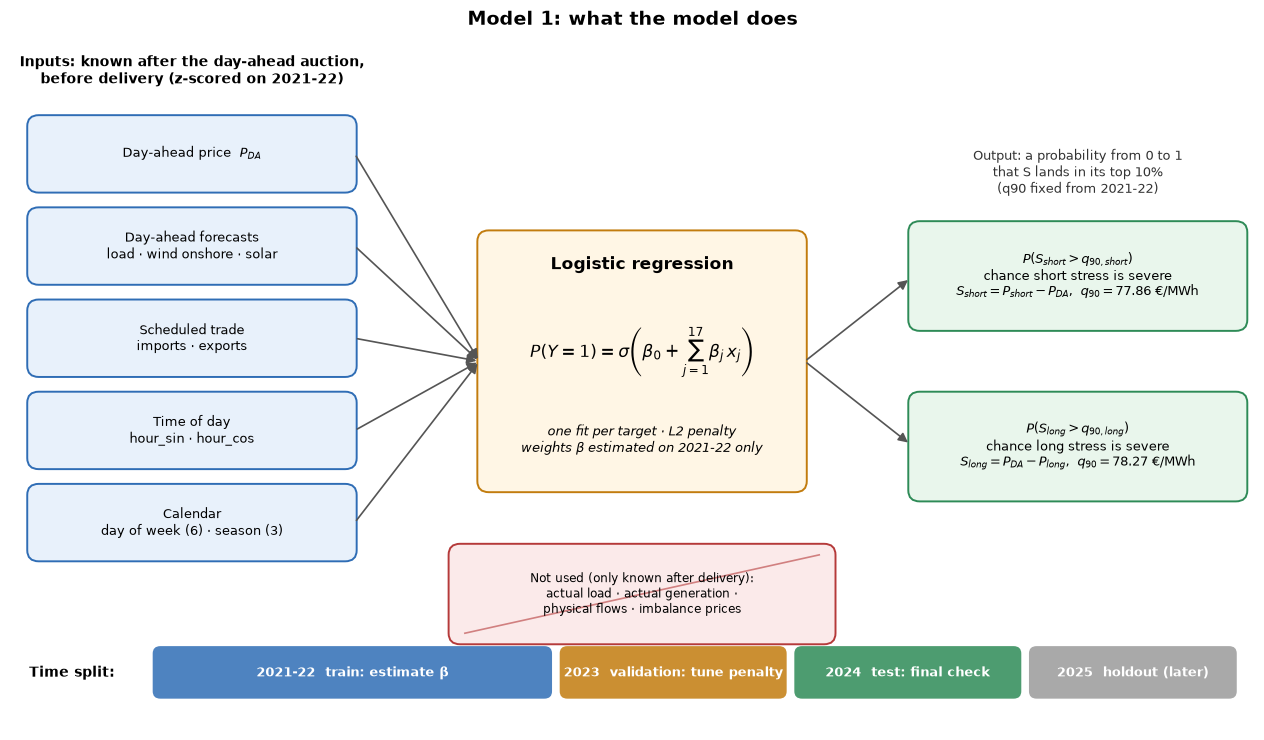

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 7.5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 7.5)
ax.axis("off")

def box(x, y, w, h, text, face, edge, size=10, weight="normal"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=face, edgecolor=edge, linewidth=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size, weight=weight)

def arrow(x0, y0, x1, y1, color="#555555"):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14,
                                 color=color, linewidth=1.2))

ax.text(1.9, 7.15, "Inputs: known after the day-ahead auction,\nbefore delivery (z-scored on 2021-22)",
        ha="center", va="center", fontsize=10, weight="bold")
inputs = ["Day-ahead price  $P_{DA}$",
          "Day-ahead forecasts\nload · wind onshore · solar",
          "Scheduled trade\nimports · exports",
          "Time of day\nhour_sin · hour_cos",
          "Calendar\nday of week (6) · season (3)"]
ys = [5.85, 4.85, 3.85, 2.85, 1.85]
for y, t in zip(ys, inputs):
    box(0.2, y, 3.4, 0.8, t, "#E8F1FB", "#2F6DB5", size=9.5)

mx, my, mw, mh = 4.9, 2.6, 3.4, 2.8
box(mx, my, mw, mh, "", "#FFF6E5", "#C27C0E")
ax.text(mx + mw / 2, my + mh - 0.4, "Logistic regression", ha="center", fontsize=12, weight="bold")
ax.text(mx + mw / 2, my + mh / 2 + 0.1, r"$P(Y=1)=\sigma\left(\beta_0+\sum_{j=1}^{17}\beta_j\,x_j\right)$",
        ha="center", va="center", fontsize=12.5)
ax.text(mx + mw / 2, my + 0.55, "one fit per target · L2 penalty\nweights β estimated on 2021-22 only",
        ha="center", va="center", fontsize=9, style="italic")
for y in ys:
    arrow(3.6, y + 0.4, mx, my + mh / 2)

q_s, q_l = saved["q90_short"], saved["q90_long"]
box(9.4, 4.35, 3.5, 1.15, r"$P(S_{short} > q_{90,short})$" + "\nchance short stress is severe\n"
    + r"$S_{short}=P_{short}-P_{DA}$,  " + f"$q_{{90}}={q_s:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
box(9.4, 2.5, 3.5, 1.15, r"$P(S_{long} > q_{90,long})$" + "\nchance long stress is severe\n"
    + r"$S_{long}=P_{DA}-P_{long}$,  " + f"$q_{{90}}={q_l:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
arrow(mx + mw, my + mh / 2, 9.4, 4.9)
arrow(mx + mw, my + mh / 2, 9.4, 3.1)
ax.text(11.15, 6.05, "Output: a probability from 0 to 1\nthat S lands in its top 10%\n(q90 fixed from 2021-22)",
        ha="center", va="center", fontsize=9, color="#333333")

box(4.6, 0.95, 4.0, 1.05, "Not used (only known after delivery):\nactual load · actual generation ·\n"
    "physical flows · imbalance prices", "#FBEAEA", "#B53A3A", size=8.5)
ax.plot([4.75, 8.45], [1.05, 1.9], color="#B53A3A", linewidth=1.2, alpha=0.6)

ax.text(0.2, 0.62, "Time split:", fontsize=10, weight="bold", va="center")
for label, x, w, c in [("2021-22  train: estimate β", 1.5, 4.2, "#2F6DB5"),
                       ("2023  validation: tune penalty", 5.75, 2.4, "#C27C0E"),
                       ("2024  test: final check", 8.2, 2.4, "#2E8B57"),
                       ("2025  holdout (later)", 10.65, 2.2, "#9A9A9A")]:
    ax.add_patch(FancyBboxPatch((x, 0.35), w - 0.05, 0.55, boxstyle="round,pad=0.01,rounding_size=0.08",
                                facecolor=c, edgecolor="none", alpha=0.85))
    ax.text(x + (w - 0.05) / 2, 0.62, label, ha="center", va="center", fontsize=9, color="white",
            weight="bold")

ax.set_title("Model 1: what the model does", fontsize=14, weight="bold", pad=10)
plt.tight_layout()
plt.show()